# Forecast evaluation: all models

1. Loads the hourly QC measurements (made in `data_QC_check.ipynb`)
2. Loads all forecast files and calculate the forecast horizon
3. Checks the forecast files (copies, repeated columns, impossible values)
4. Looks at forecast vs. measured for some days
5. RMSE and bias for each model and each forecast horizon
6. Which days are easier to forecast: clear, broken clouds or overcast?
7. Blended forecast (forecast competition)

In [88]:
import glob
import os
import re
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from scipy.optimize import nnls

## Settings

In [89]:
station_id = '06123'
latitude = 55.2493     # same values as in data_QC_check.ipynb
longitude = 9.8899

models = ['dmi_harmonie_arome_europe', 'metno_nordic', 'ecmwf_ifs025', 'ecmwf_aifs025_single',
          'gfs_global', 'ecmwf_ifs', 'dmi_seamless', 'gfs_seamless']

measurement_file = 'dmi_' + station_id + '_hourly_qc.csv'

# Forecast files can be in this folder or in the 'Forecast data' folder
forecast_files = glob.glob(station_id + '_*.csv') + glob.glob('Forecast data/' + station_id + '_*.csv')
forecast_files = sorted(forecast_files)
print('Number of forecast files:', len(forecast_files))

location = pvlib.location.Location(latitude, longitude)

Number of forecast files: 2


## 1. Load the measurements

In [90]:
measured = pd.read_csv(measurement_file, index_col=0)
measured.index = pd.to_datetime(measured.index, utc=True)
measured = measured['ghi']

print('Measurements from', measured.index[0], 'to', measured.dropna().index[-1])

Measurements from 2025-11-01 00:00:00+00:00 to 2026-11-05 13:00:00+00:00


## 2. Load the forecasts

The file name gives the time the forecast was made, e.g. `06123_20261103T1100.csv` was made 2026-11-03 11:00 UTC.

The **forecast horizon** is the time between when the forecast was made and the time it is for:
* forecast made 11:00, timestamp 12:00 (= 11:01–12:00) -> horizon 1 hour
* timestamp 13:00 -> horizon 2 hours, and so on

The files also contain hours before the forecast was made (horizon ≤ 0). These are not real forecasts, so we remove them.

Not every model forecasts 7 days ahead: e.g. DMI Harmonie stops after 54 hours, so those cells are empty (NaN).

All forecasts are put into one long table with the columns: issue time, time, horizon, model, forecast, measured.

In [91]:
all_rows = []

for file in forecast_files:
    # Forecast issue time from the file name: '06123_20261103T1100.csv' -> '20261103T1100'
    name = os.path.basename(file)
    match = re.search(r'(\d{8}T\d{4})', name)
    if match is None:
        print('Skipping, no issue time in file name:', name)
        continue
    issue_time = pd.to_datetime(match.group(1), format='%Y%m%dT%H%M', utc=True)

    forecast = pd.read_csv(file, index_col=0)
    forecast.index = pd.to_datetime(forecast.index, utc=True)

    for model in models:
        if model not in forecast.columns:
            continue
        table = pd.DataFrame()
        table['time'] = forecast.index
        table['forecast'] = forecast[model].values
        table['model'] = model
        table['issue_time'] = issue_time
        table['horizon'] = (table['time'] - issue_time) / pd.Timedelta(hours=1)
        table['file'] = name
        all_rows.append(table)

fc = pd.concat(all_rows, ignore_index=True)

# If the same forecast is in the folder twice (e.g. a '... - Copy.csv'), keep it only once
fc = fc.drop_duplicates(subset=['issue_time', 'model', 'time'])

# Keep only real forecasts (horizon of 1 hour or more)
fc = fc[fc['horizon'] >= 1].copy()
fc['horizon'] = fc['horizon'].astype(int)

# Add the measured value for the same timestamp
fc['measured'] = measured.reindex(fc['time']).values

# Number of forecast files for each model (older files may not have all 8 columns)
print(fc.groupby('model')['issue_time'].nunique().reindex(models))
fc.head()

model
dmi_harmonie_arome_europe    2
metno_nordic                 2
ecmwf_ifs025                 2
ecmwf_aifs025_single         2
gfs_global                   2
ecmwf_ifs                    2
dmi_seamless                 1
gfs_seamless                 1
Name: issue_time, dtype: int64


,time,forecast,model,issue_time,horizon,file,measured
12,2026-11-03 12:00:00+00:00,439.0,dmi_harmonie_arome_europe,2026-11-03 11:00:00+00:00,1,06123_20261103T1100.csv,140.166667
13,2026-11-03 13:00:00+00:00,227.0,dmi_harmonie_arome_europe,2026-11-03 11:00:00+00:00,2,06123_20261103T1100.csv,132.666667
14,2026-11-03 14:00:00+00:00,56.0,dmi_harmonie_arome_europe,2026-11-03 11:00:00+00:00,3,06123_20261103T1100.csv,151.166667
15,2026-11-03 15:00:00+00:00,0.0,dmi_harmonie_arome_europe,2026-11-03 11:00:00+00:00,4,06123_20261103T1100.csv,43.833333
16,2026-11-03 16:00:00+00:00,0.0,dmi_harmonie_arome_europe,2026-11-03 11:00:00+00:00,5,06123_20261103T1100.csv,2.166667


### Sun position and clear-sky GHI
Calculated in the middle of each hour, because the timestamps are right-labeled (12:00 = 11:01–12:00).
The clear-sky GHI (Ineichen model) is what GHI would be without clouds. It is used to check the forecasts and to sort the days into clear / cloudy.

In [92]:
unique_times = pd.DatetimeIndex(sorted(fc['time'].unique()))
middle_of_hour = unique_times - pd.Timedelta(minutes=30)
solpos = location.get_solarposition(middle_of_hour)
clearsky = location.get_clearsky(middle_of_hour, solar_position=solpos)

sun = pd.DataFrame({'elevation': solpos['elevation'].values,
                    'ghi_clear': clearsky['ghi'].values}, index=unique_times)

fc['elevation'] = sun['elevation'].reindex(fc['time']).values
fc['ghi_clear'] = sun['ghi_clear'].reindex(fc['time']).values

## 3. Check the forecast files

**a) Impossible values.** A forecast above 0 when the sun is below the horizon, or far above clear-sky, means something is wrong with the file (e.g. wrong time zone or wrong location). Add such files to `bad_files` to leave them out.

In [93]:
night = fc[(fc['elevation'] < -2) & (fc['forecast'] > 10)]
too_high = fc[(fc['elevation'] > 5) & (fc['forecast'] > 1.3 * fc['ghi_clear'] + 50)]

print('Files with forecast GHI while the sun is down:')
print(night.groupby('file').size().to_string() if len(night) else '  none')
print()
print('Files with forecast GHI far above clear-sky:')
print(too_high.groupby('file').size().to_string() if len(too_high) else '  none')

Files with forecast GHI while the sun is down:
file
06123_20261103T1100.csv    150

Files with forecast GHI far above clear-sky:
file
06123_20261103T1100.csv    171


In [94]:
bad_files = ['06123_20261103T1100.csv']      # e.g. ['06123_20261103T1100.csv']

fc = fc[~fc['file'].isin(bad_files)]

**b) Repeated columns.** How often two models give exactly the same value.
Some overlap is expected: the `_seamless` models are built from other models
(`dmi_seamless` = DMI Harmonie for the first 2-3 days and ECMWF after that, `gfs_seamless` is mostly GFS).
Keep this in mind in the discussion: those models are not independent forecasts.

In [95]:
wide = fc[fc['elevation'] > 0].pivot_table(index=['issue_time', 'time'], columns='model', values='forecast')

rows = []
for a, b in itertools.combinations(models, 2):
    if a in wide.columns and b in wide.columns:
        both = wide[[a, b]].dropna()
        if len(both) > 0:
            rows.append({'model_a': a, 'model_b': b, 'n': len(both),
                         'identical_%': 100 * (both[a] == both[b]).mean()})

same = pd.DataFrame(rows).sort_values('identical_%', ascending=False)
same[same['identical_%'] > 20].round(1)

,model_a,model_b,n,identical_%
5,dmi_harmonie_arome_europe,dmi_seamless,17,100.0
24,gfs_global,gfs_seamless,49,100.0
25,ecmwf_ifs,dmi_seamless,49,65.3


### Remove night-time hours
At night both forecast and measurement are 0. Those hours are "perfect" and would make the errors look smaller than they really are, so we only use hours where the sun is up (sun elevation > 0 in the middle of the hour).

In [96]:
# Only daytime hours where we have both a forecast and a measurement
data = fc[(fc['elevation'] > 0) & fc['measured'].notna() & fc['forecast'].notna()].copy()
data['error'] = data['forecast'] - data['measured']

print('Forecast/measurement pairs used:', len(data))
print(data.groupby('model').size().reindex(models))

Forecast/measurement pairs used: 120
model
dmi_harmonie_arome_europe    15
metno_nordic                 15
ecmwf_ifs025                 15
ecmwf_aifs025_single         15
gfs_global                   15
ecmwf_ifs                    15
dmi_seamless                 15
gfs_seamless                 15
dtype: int64


## 4. Forecast vs. measured
This plots the forecast from the newest file that has measurements, along with the measured GHI and clear-sky GHI. Change `file_number` to look at other forecast files.

Issue times with measurements: 1


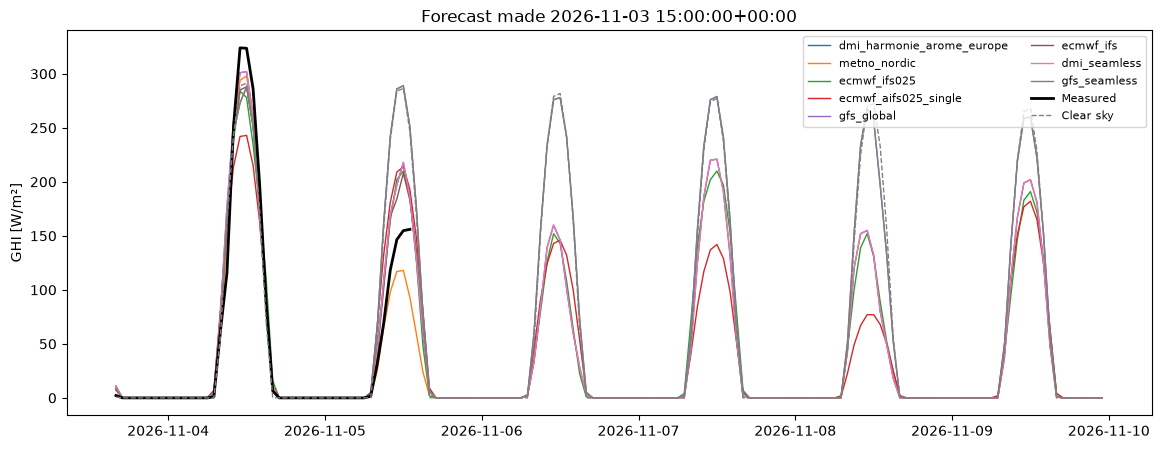

In [97]:
issue_times = sorted(data['issue_time'].unique())
print('Issue times with measurements:', len(issue_times))

if len(issue_times) == 0:
    print('No issue times available in filtered data.')
else:
    file_number = -1
    issue = issue_times[file_number]
    one = fc[fc['issue_time'] == issue]

    plt.figure(figsize=(14, 5))
    for model in models:
        m = one[one['model'] == model]
        plt.plot(m['time'], m['forecast'], label=model, linewidth=1)

    m = one.drop_duplicates('time')
    plt.plot(m['time'], m['measured'], color='black', linewidth=2, label='Measured')
    plt.plot(m['time'], m['ghi_clear'], color='grey', linestyle='--', linewidth=1, label='Clear sky')

    plt.ylabel('GHI [W/m²]')
    plt.title('Forecast made ' + str(issue))
    plt.legend(fontsize=8, ncol=2)
    plt.show()

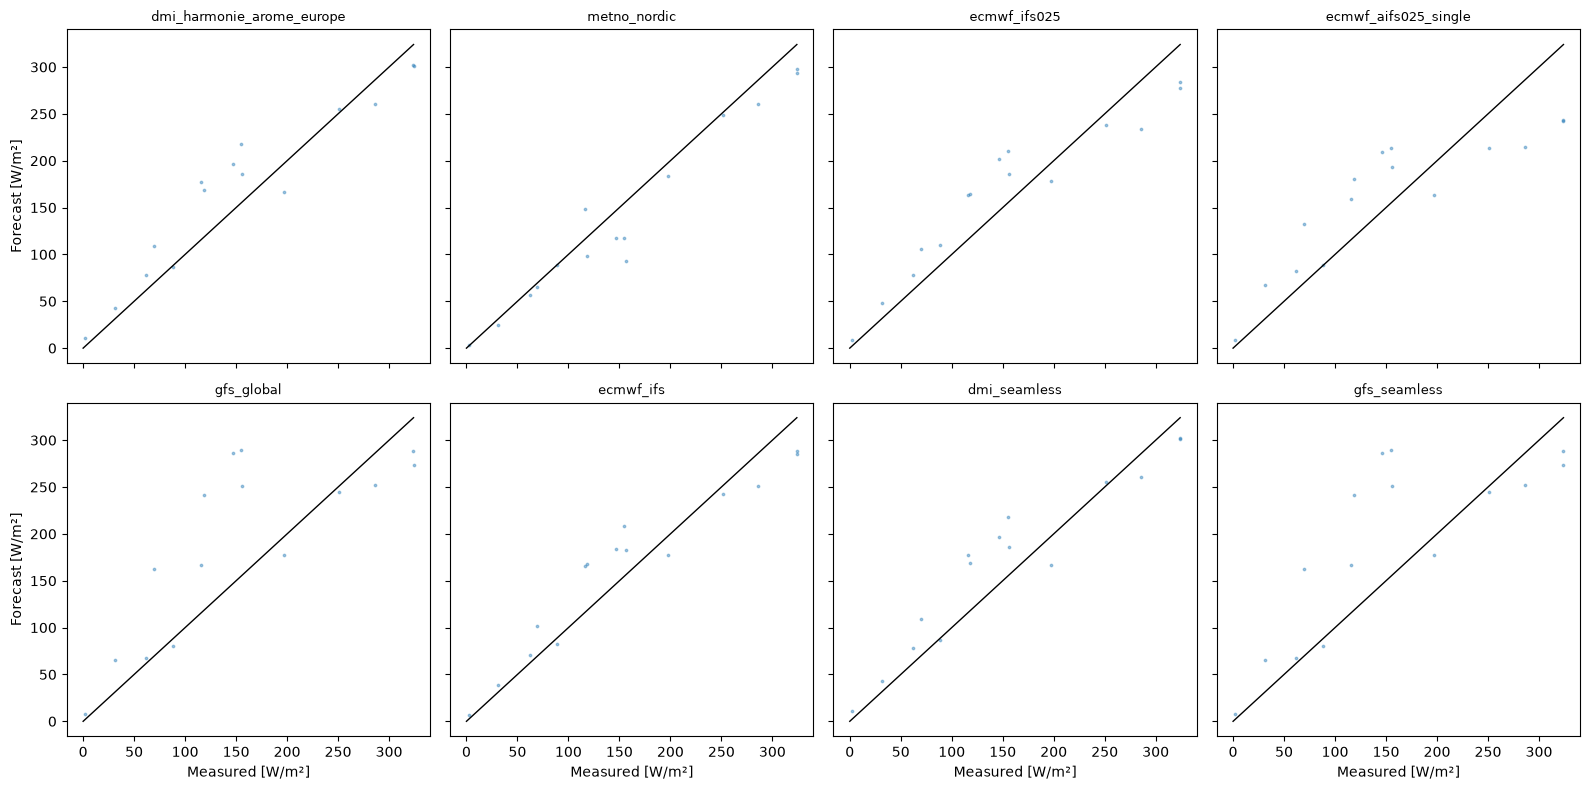

In [98]:
# Scatter plot: forecast vs. measured, one subplot per model
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
axes = axes.flatten()

max_value = data[['measured', 'forecast']].max().max()
for ax, model in zip(axes, models):
    m = data[data['model'] == model]
    ax.scatter(m['measured'], m['forecast'], s=3, alpha=0.4)
    ax.plot([0, max_value], [0, max_value], color='black', linewidth=1)   # the 1:1 line
    ax.set_title(model, fontsize=9)

for ax in axes[4:]:
    ax.set_xlabel('Measured [W/m²]')
axes[0].set_ylabel('Forecast [W/m²]')
axes[4].set_ylabel('Forecast [W/m²]')
plt.tight_layout()
plt.show()

## 5. RMSE and bias

* **Bias** = mean(forecast − measured). Positive means the model forecasts too much on average.
* **RMSE** = sqrt(mean((forecast − measured)²)). Large errors count more.

Both are calculated for every model and every forecast horizon. The relative values are divided by the mean measured GHI.

Note: models with a short horizon (Harmonie, MetNo Nordic) are only scored on the first ~2.5 days, so their overall score is not directly comparable to the global models. The per-horizon plot is the fair comparison.

In [99]:
def bias(error):
    return error.mean()

def rmse(error):
    return np.sqrt((error**2).mean())

# Overall scores per model (all horizons together)
overall = data.groupby('model')['error'].agg([bias, rmse])
overall['mean_measured'] = data.groupby('model')['measured'].mean()
overall['rel_bias_%'] = 100 * overall['bias'] / overall['mean_measured']
overall['rel_rmse_%'] = 100 * overall['rmse'] / overall['mean_measured']
overall['max_horizon_h'] = data.groupby('model')['horizon'].max()
overall.sort_values('rmse').round(1)

,bias,rmse,mean_measured,rel_bias_%,rel_rmse_%,max_horizon_h
model,,,,,,
metno_nordic,-15.3,26.0,155.1,-9.8,16.8,46
ecmwf_ifs,8.5,32.4,155.1,5.5,20.9,46
dmi_seamless,15.6,35.0,155.1,10.1,22.5,46
dmi_harmonie_arome_europe,15.6,35.0,155.1,10.1,22.5,46
ecmwf_ifs025,10.7,37.1,155.1,6.9,23.9,46
ecmwf_aifs025_single,5.7,52.4,155.1,3.7,33.8,46
gfs_global,35.2,73.0,155.1,22.7,47.0,46
gfs_seamless,35.2,73.0,155.1,22.7,47.0,46


In [100]:
# Scores per model and per horizon
scores = data.groupby(['model', 'horizon'])['error'].agg([bias, rmse])
scores['n'] = data.groupby(['model', 'horizon']).size()
scores = scores.reset_index()
scores.head()

,model,horizon,bias,rmse,n
0,dmi_harmonie_arome_europe,1,8.833333,8.833333,1
1,dmi_harmonie_arome_europe,17,16.000000,16.000000,1
2,dmi_harmonie_arome_europe,18,61.166667,61.166667,1
3,dmi_harmonie_arome_europe,19,3.833333,3.833333,1
4,dmi_harmonie_arome_europe,20,-23.000000,23.000000,1


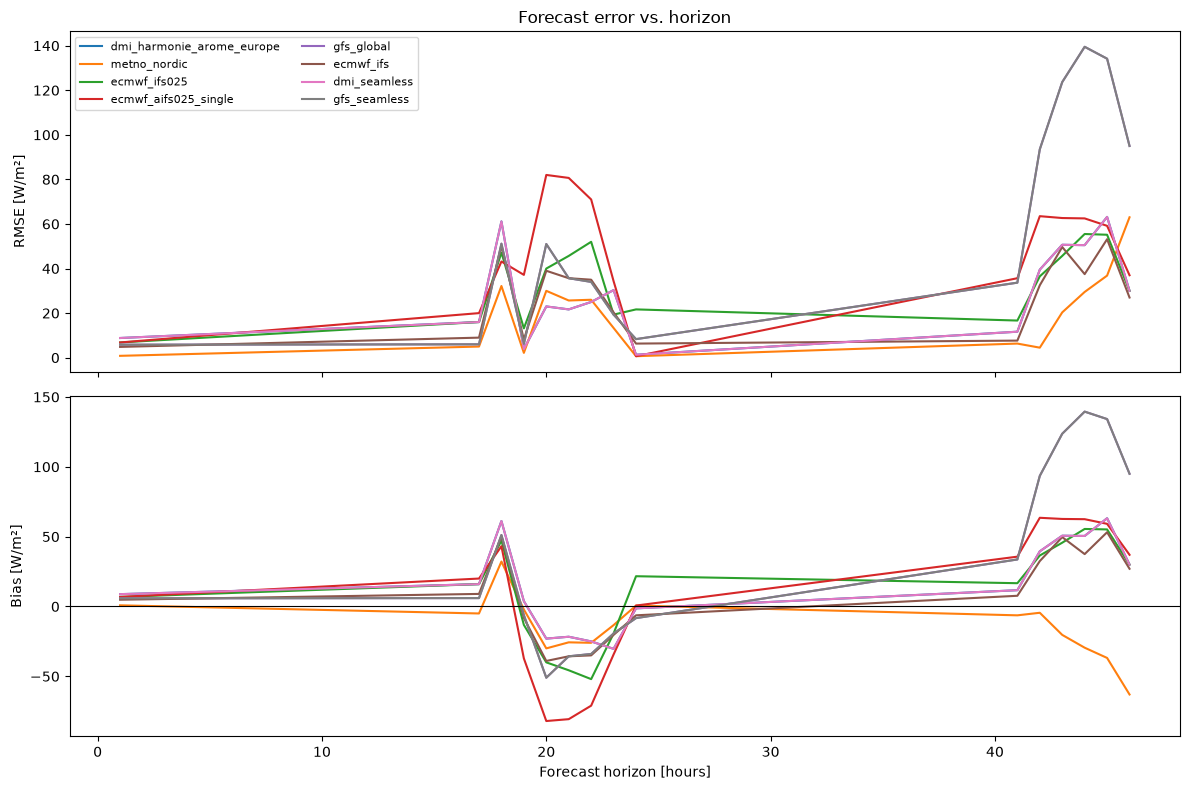

In [101]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for model in models:
    s = scores[scores['model'] == model]
    axes[0].plot(s['horizon'], s['rmse'], label=model)
    axes[1].plot(s['horizon'], s['bias'], label=model)

axes[0].set_ylabel('RMSE [W/m²]')
axes[1].set_ylabel('Bias [W/m²]')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('Forecast horizon [hours]')
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_title('Forecast error vs. horizon')
plt.tight_layout()
plt.show()

### Per forecast day
One hour horizon only has a few daytime pairs per file, so the curve above is noisy. Grouping the horizons into days (1–24 h = day 1, 25–48 h = day 2, ...) gives a smoother picture.

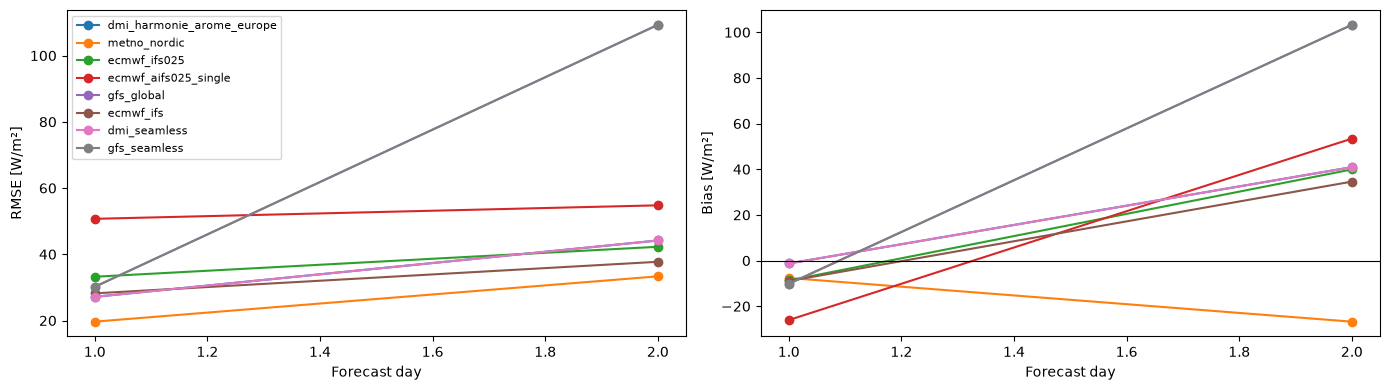

day_ahead,1,2
model,,
dmi_harmonie_arome_europe,27.2,44.2
metno_nordic,19.7,33.3
ecmwf_ifs025,33.2,42.3
ecmwf_aifs025_single,50.7,54.8
gfs_global,30.2,109.3
ecmwf_ifs,28.2,37.7
dmi_seamless,27.2,44.2
gfs_seamless,30.2,109.3


In [102]:
data['day_ahead'] = (data['horizon'] - 1) // 24 + 1

daily_scores = data.groupby(['model', 'day_ahead'])['error'].agg([bias, rmse]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for model in models:
    s = daily_scores[daily_scores['model'] == model]
    axes[0].plot(s['day_ahead'], s['rmse'], marker='o', label=model)
    axes[1].plot(s['day_ahead'], s['bias'], marker='o', label=model)

axes[0].set_ylabel('RMSE [W/m²]')
axes[1].set_ylabel('Bias [W/m²]')
axes[1].axhline(0, color='black', linewidth=0.8)
for ax in axes:
    ax.set_xlabel('Forecast day')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Table: RMSE per model (rows) and forecast day (columns)
daily_scores.pivot(index='model', columns='day_ahead', values='rmse').reindex(models).round(1)

In [103]:
# Save the scores for the poster
#scores.to_csv('scores_all_models.csv', index=False)
#daily_scores.to_csv('daily_scores_all_models.csv', index=False)

## 6. Clear, broken-cloud and overcast days

For each day: **clear-sky index** = measured daily GHI / clear-sky daily GHI.
* above 0.7 -> clear
* 0.3–0.7 -> broken clouds / partly cloudy
* below 0.3 -> overcast

(Change the limits if they don't fit station. Because overcast days have little sunlight, compare the **relative** RMSE (RMSE / mean measured) between day types)

In [104]:
meas = measured.to_frame('ghi')
meas.index.name = 'time'
cs = location.get_clearsky(meas.index - pd.Timedelta(minutes=30))
meas['ghi_clear'] = cs['ghi'].values
meas['date'] = (meas.index - pd.Timedelta(minutes=30)).date

day = meas.groupby('date').agg(measured=('ghi', 'sum'), clear=('ghi_clear', 'sum'), n=('ghi', 'count'))
day = day[day['n'] == 24].copy()            # complete days only
day['clearsky_index'] = day['measured'] / day['clear']
day['day_type'] = pd.cut(day['clearsky_index'], bins=[-1, 0.3, 0.7, 10],
                         labels=['overcast', 'broken clouds', 'clear'])

print(day['day_type'].value_counts())
day.round(2)

day_type
clear            179
broken clouds    123
overcast          57
Name: count, dtype: int64


,measured,clear,n,clearsky_index,day_type
date,,,,,
2025-11-01,602.17,1639.71,24,0.37,broken clouds
2025-11-02,1132.17,1601.50,24,0.71,clear
2025-11-03,1009.33,1564.13,24,0.65,broken clouds
2025-11-04,579.67,1527.51,24,0.38,broken clouds
2025-11-05,678.00,1491.60,24,0.45,broken clouds
...,...,...,...,...,...
2026-10-31,377.83,1690.05,24,0.22,overcast
2026-11-01,242.50,1650.79,24,0.15,overcast
2026-11-02,885.50,1612.34,24,0.55,broken clouds


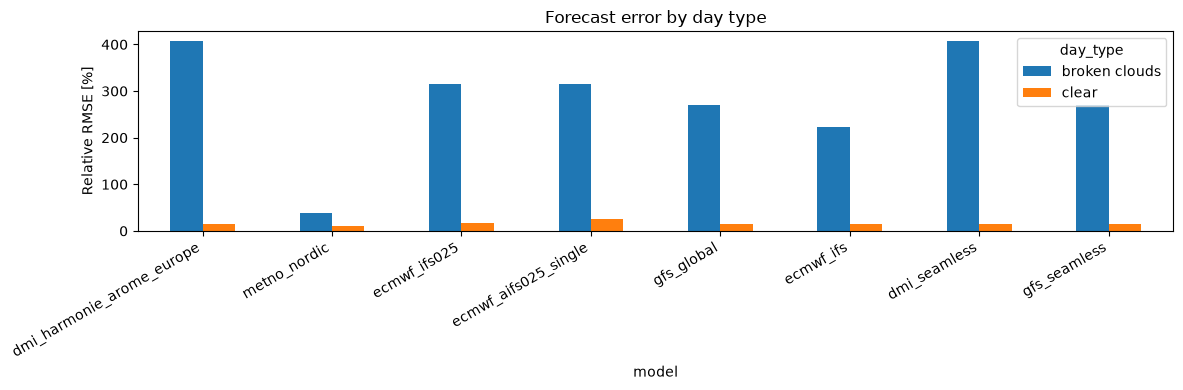

day_type,broken clouds,clear
model,,
dmi_harmonie_arome_europe,407.7,13.9
metno_nordic,38.5,10.1
ecmwf_ifs025,315.4,17.1
ecmwf_aifs025_single,315.4,26.1
gfs_global,269.2,15.5
ecmwf_ifs,223.1,14.5
dmi_seamless,407.7,13.9
gfs_seamless,269.2,15.5


In [105]:
data['date'] = (pd.DatetimeIndex(data['time']) - pd.Timedelta(minutes=30)).date
data['day_type'] = data['date'].map(day['day_type'])

type_scores = data.dropna(subset=['day_type']).groupby(['model', 'day_type'], observed=True).agg(
    bias=('error', bias), rmse=('error', rmse), mean_measured=('measured', 'mean'))
type_scores['rel_rmse_%'] = 100 * type_scores['rmse'] / type_scores['mean_measured']

table = type_scores['rel_rmse_%'].unstack().reindex(models)
table.plot.bar(figsize=(12, 4))
plt.ylabel('Relative RMSE [%]')
plt.title('Forecast error by day type')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

table.round(1)

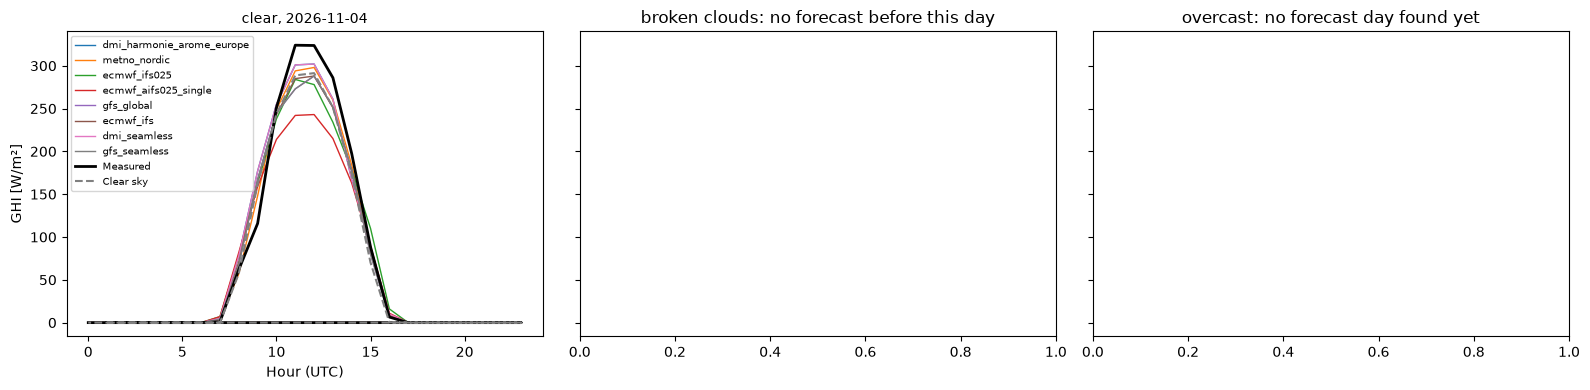

In [107]:

example_number = 0      

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, day_type in zip(axes, ['clear', 'broken clouds', 'overcast']):
    dates = [d for d in day.index[day['day_type'] == day_type] if d in set(data['date'])]
    if len(dates) <= example_number:
        ax.set_title(day_type + ': no forecast day found yet')
        continue
    start = pd.Timestamp(dates[example_number], tz='UTC')
    earlier = fc.loc[fc['issue_time'] <= start, 'issue_time']
    if len(earlier) == 0:
        ax.set_title(day_type + ': no forecast before this day')
        continue
    issue = earlier.max()
    one = fc[(fc['issue_time'] == issue) & (fc['time'] > start) & (fc['time'] <= start + pd.Timedelta(days=1))]
    for model in models:
        m = one[one['model'] == model]
        ax.plot(m['time'].dt.hour, m['forecast'], label=model, linewidth=1)
    m = one.drop_duplicates('time')
    ax.plot(m['time'].dt.hour, m['measured'], color='black', linewidth=2, label='Measured')
    ax.plot(m['time'].dt.hour, m['ghi_clear'], color='grey', linestyle='--', label='Clear sky')
    ax.set_title(day_type + ', ' + str(dates[example_number]), fontsize=10)
    ax.set_xlabel('Hour (UTC)')

axes[0].set_ylabel('GHI [W/m²]')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 7. Blended forecast for competition



